# Example 5 — Hitmap and photon rate

A hitmap is each macropixel's occupancy over the acquisition: how many photons
it registered, and at what rate. It is the first thing to look at under light.
It shows where the beam or the SPDC rings fall, which pixels to pick for
[coincidences](06_coincidences.ipynb), and whether anything is saturating.

Full explanation: [Hitmaps](../docs/guide/hitmap.md).

## What you need

- a folder of `.bin` files from any program:
  - `ORT`, `S0T`, ... (timestamping): a count is a frame carrying a valid
    first-photon timestamp, so at most one per pixel per frame;
  - `ORC`, `S0C`, ... (counting): the per-frame photon counter, summed;
- `nframes`, the frames per file you acquired with. Do not infer it from the
  file size: the acquisition exe dumps a fixed memory region larger than the
  acquisition.
- the firmware and its exposure setting, recorded in the sidecar.

## 1. Point dapkel at the data

In [1]:
import glob
import os

from IPython.display import Image, display


def show_figures(folder, kind):
    """Show the figures plot_* saved to results/<kind>/ (it closes them)."""
    for png in sorted(glob.glob(os.path.join(folder, "results", kind, "*.png"))):
        display(Image(filename=png))

In [2]:
import numpy as np

from dapkel.functions import hitmap_analysis as hm

path = r"D:\Kelpie\2026.10.30"
nframes = 10_000
tag = "ORT"

## 2. Accumulate and save

`process_hitmap` saves the `(32, 32)` counts to
`processed/<folder>_ort_hitmap.npy`. The sidecar records the frame count and
the live time, which the rate map needs later.

In [3]:
# current firmware: 9 µs cycle, 100 ns open shutter inside it
hm.process_hitmap(path, nframes, tag, open_shutter_time_s=100e-9)

# legacy firmware: you set X, the firmware adds 9 µs
# hm.process_hitmap(path, nframes, tag, firmware_version="long_exposure", exp_time_s=91e-6)

# a quick look on part of the run
# hm.process_hitmap(path, nframes, tag, open_shutter_time_s=100e-9, max_files=10)


> > > Computing the 'ORT' hitmap < < <



ORT: 100%|██████████| 10/10 [00:06<00:00,  1.52it/s]

  total 2635528  median 1524  max 70992

> > > Hitmap saved to D:\Kelpie\2026.10.30\processed\2026.10.30_ort_hitmap.npy < < <


'D:\\Kelpie\\2026.10.30\\processed\\2026.10.30_ort_hitmap.npy'

## 3. Plot counts and rate

`plot_hitmap` writes two figures to `results/hitmap/`:

- `<folder>_ort_hitmap.png`: the counts;
- `<folder>_ort_hitmap_rate.png`: the rate.

It returns both arrays. The rate is

```
photons / (total frames × frame cycle)
```

where the frame cycle is 9 µs, or the live time if that is longer (legacy
firmware). The shutter does not enter: it can be shorter than the cycle, but
every frame still takes a full cycle.


> > > Plot is saved as 2026.10.30_ort_hitmap.png in D:\Kelpie\2026.10.30\results\hitmap < < <

> > > Plot is saved as 2026.10.30_ort_hitmap_rate.png in D:\Kelpie\2026.10.30\results\hitmap < < <
  100000 frames x 9 us = 900.000 ms;  rate median 1.69e+03  max 7.89e+04 Hz


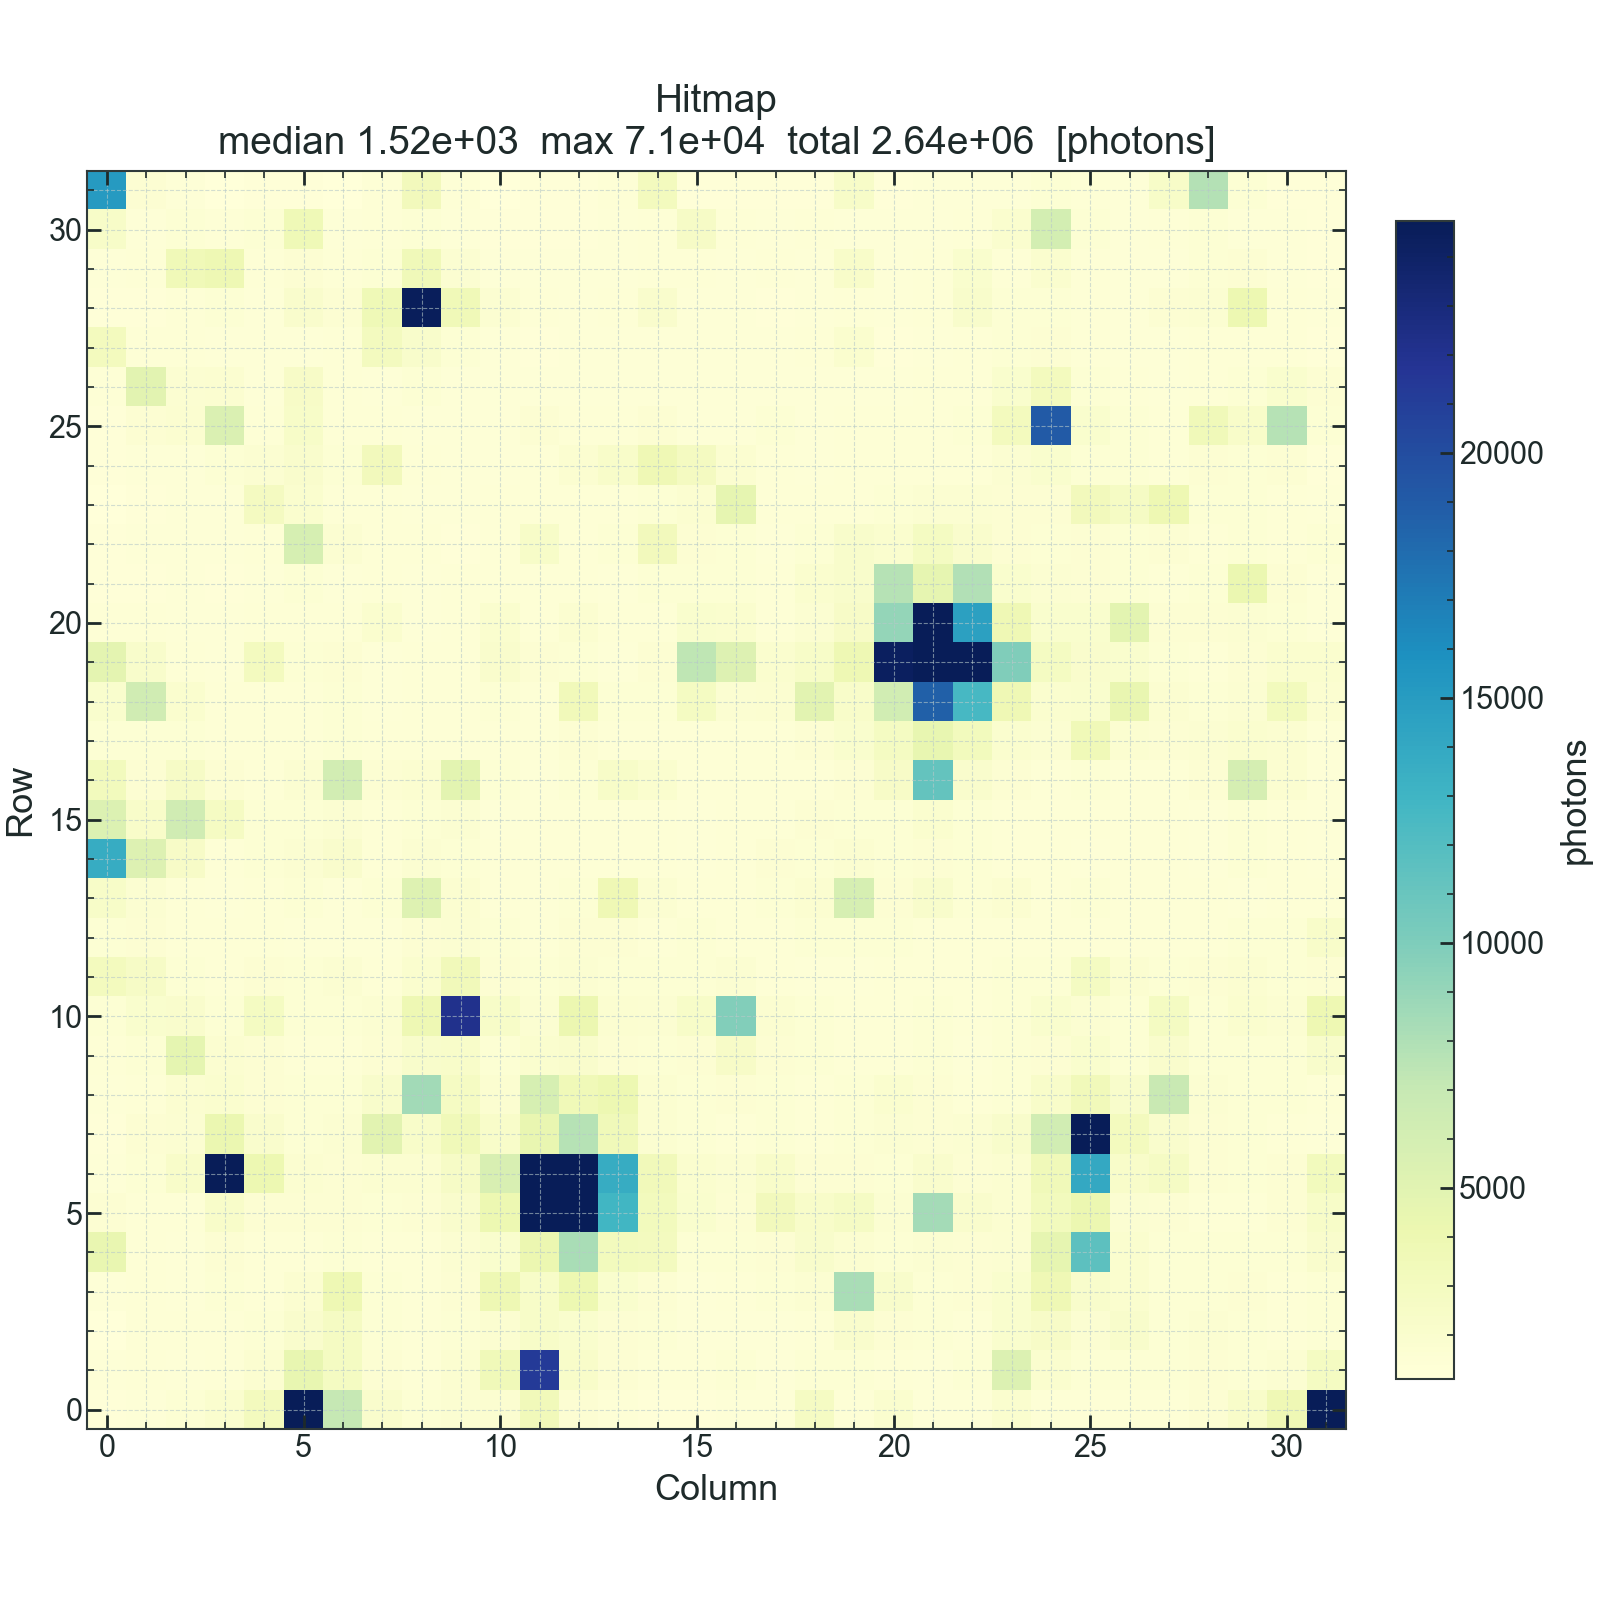

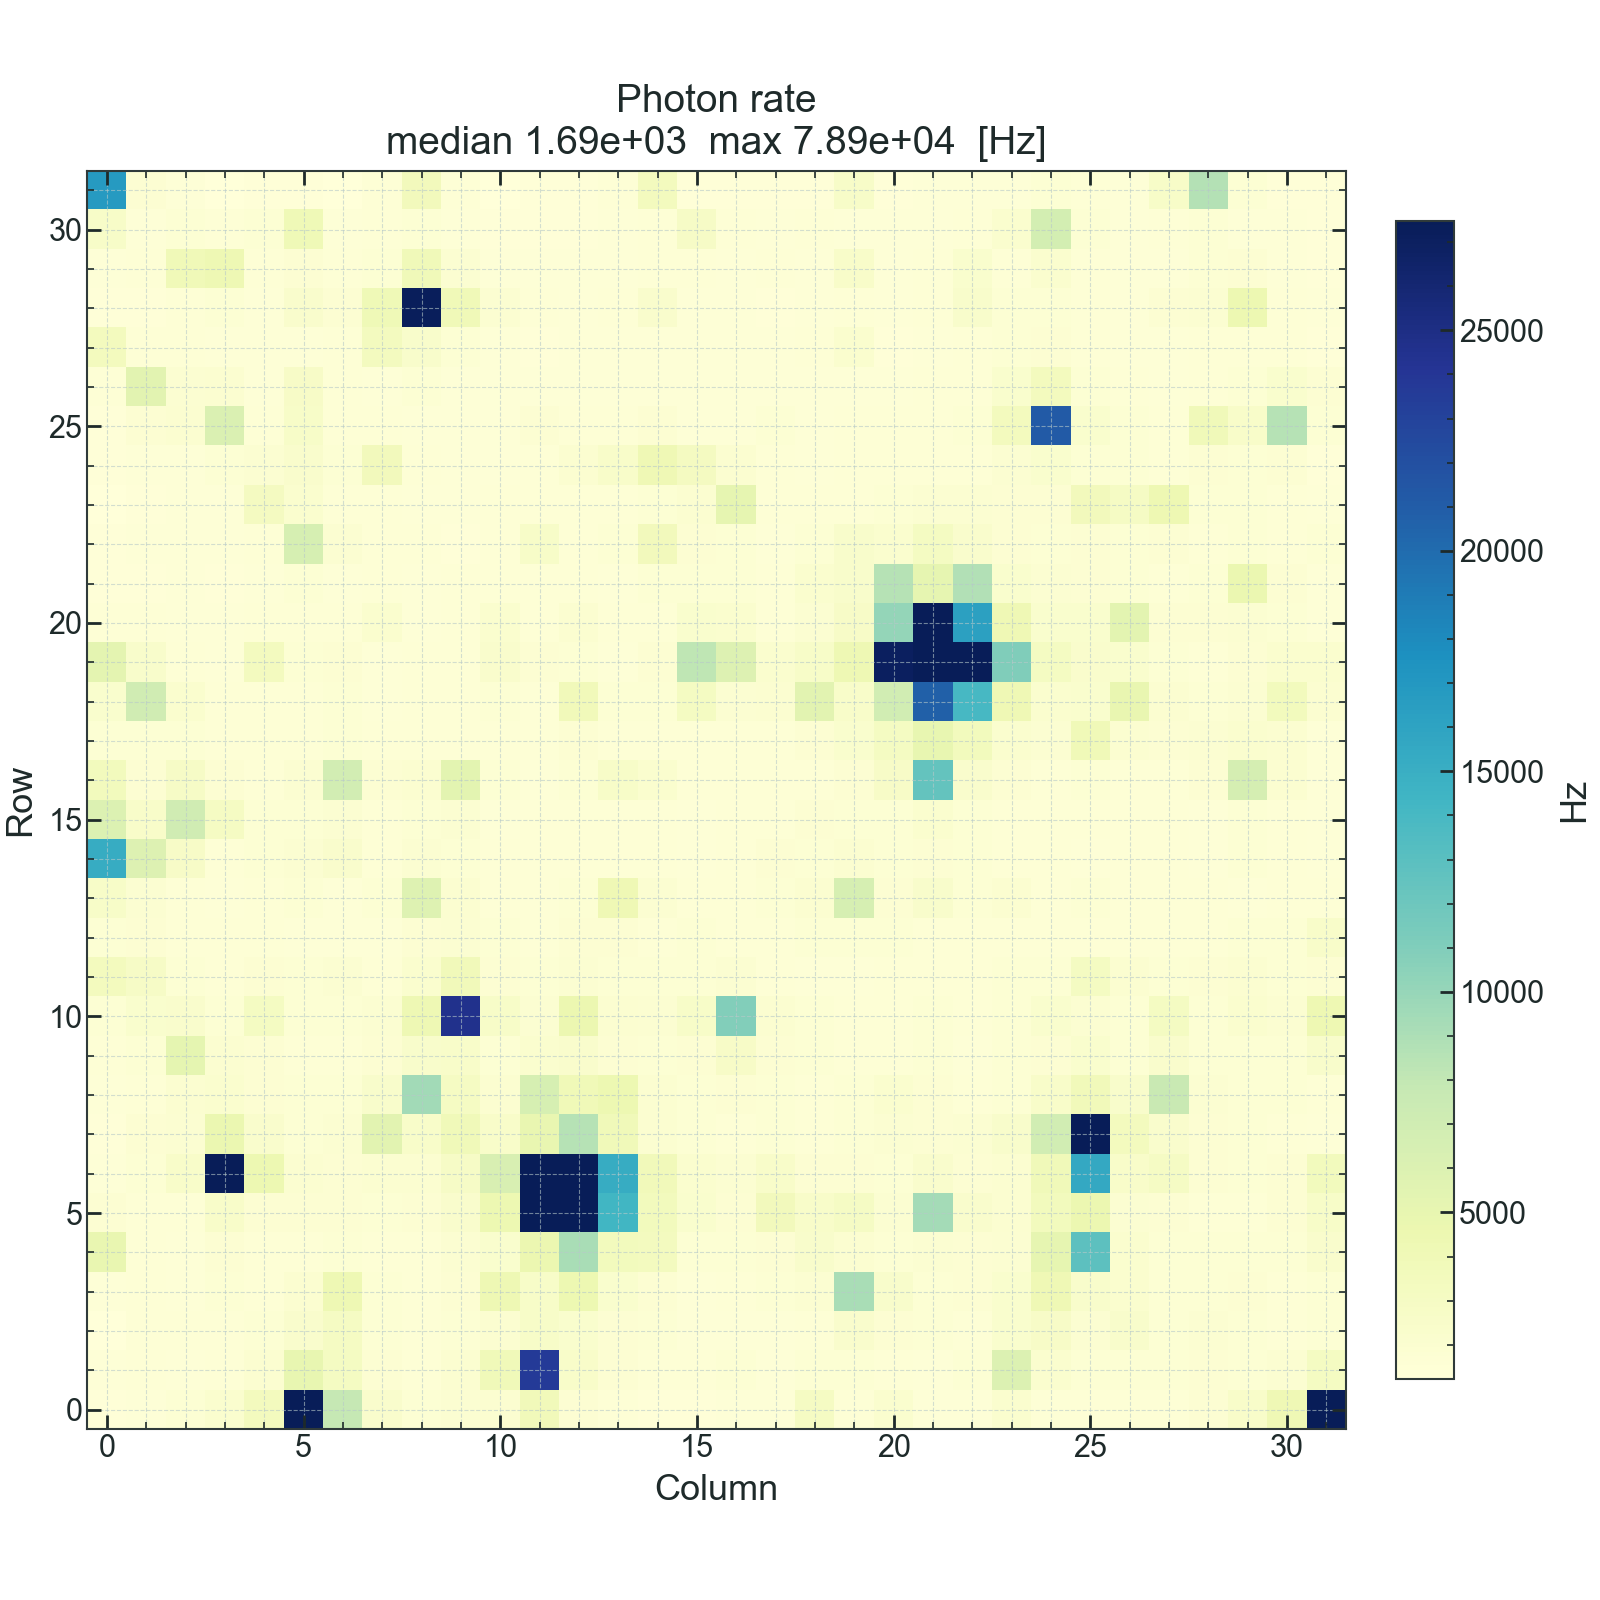

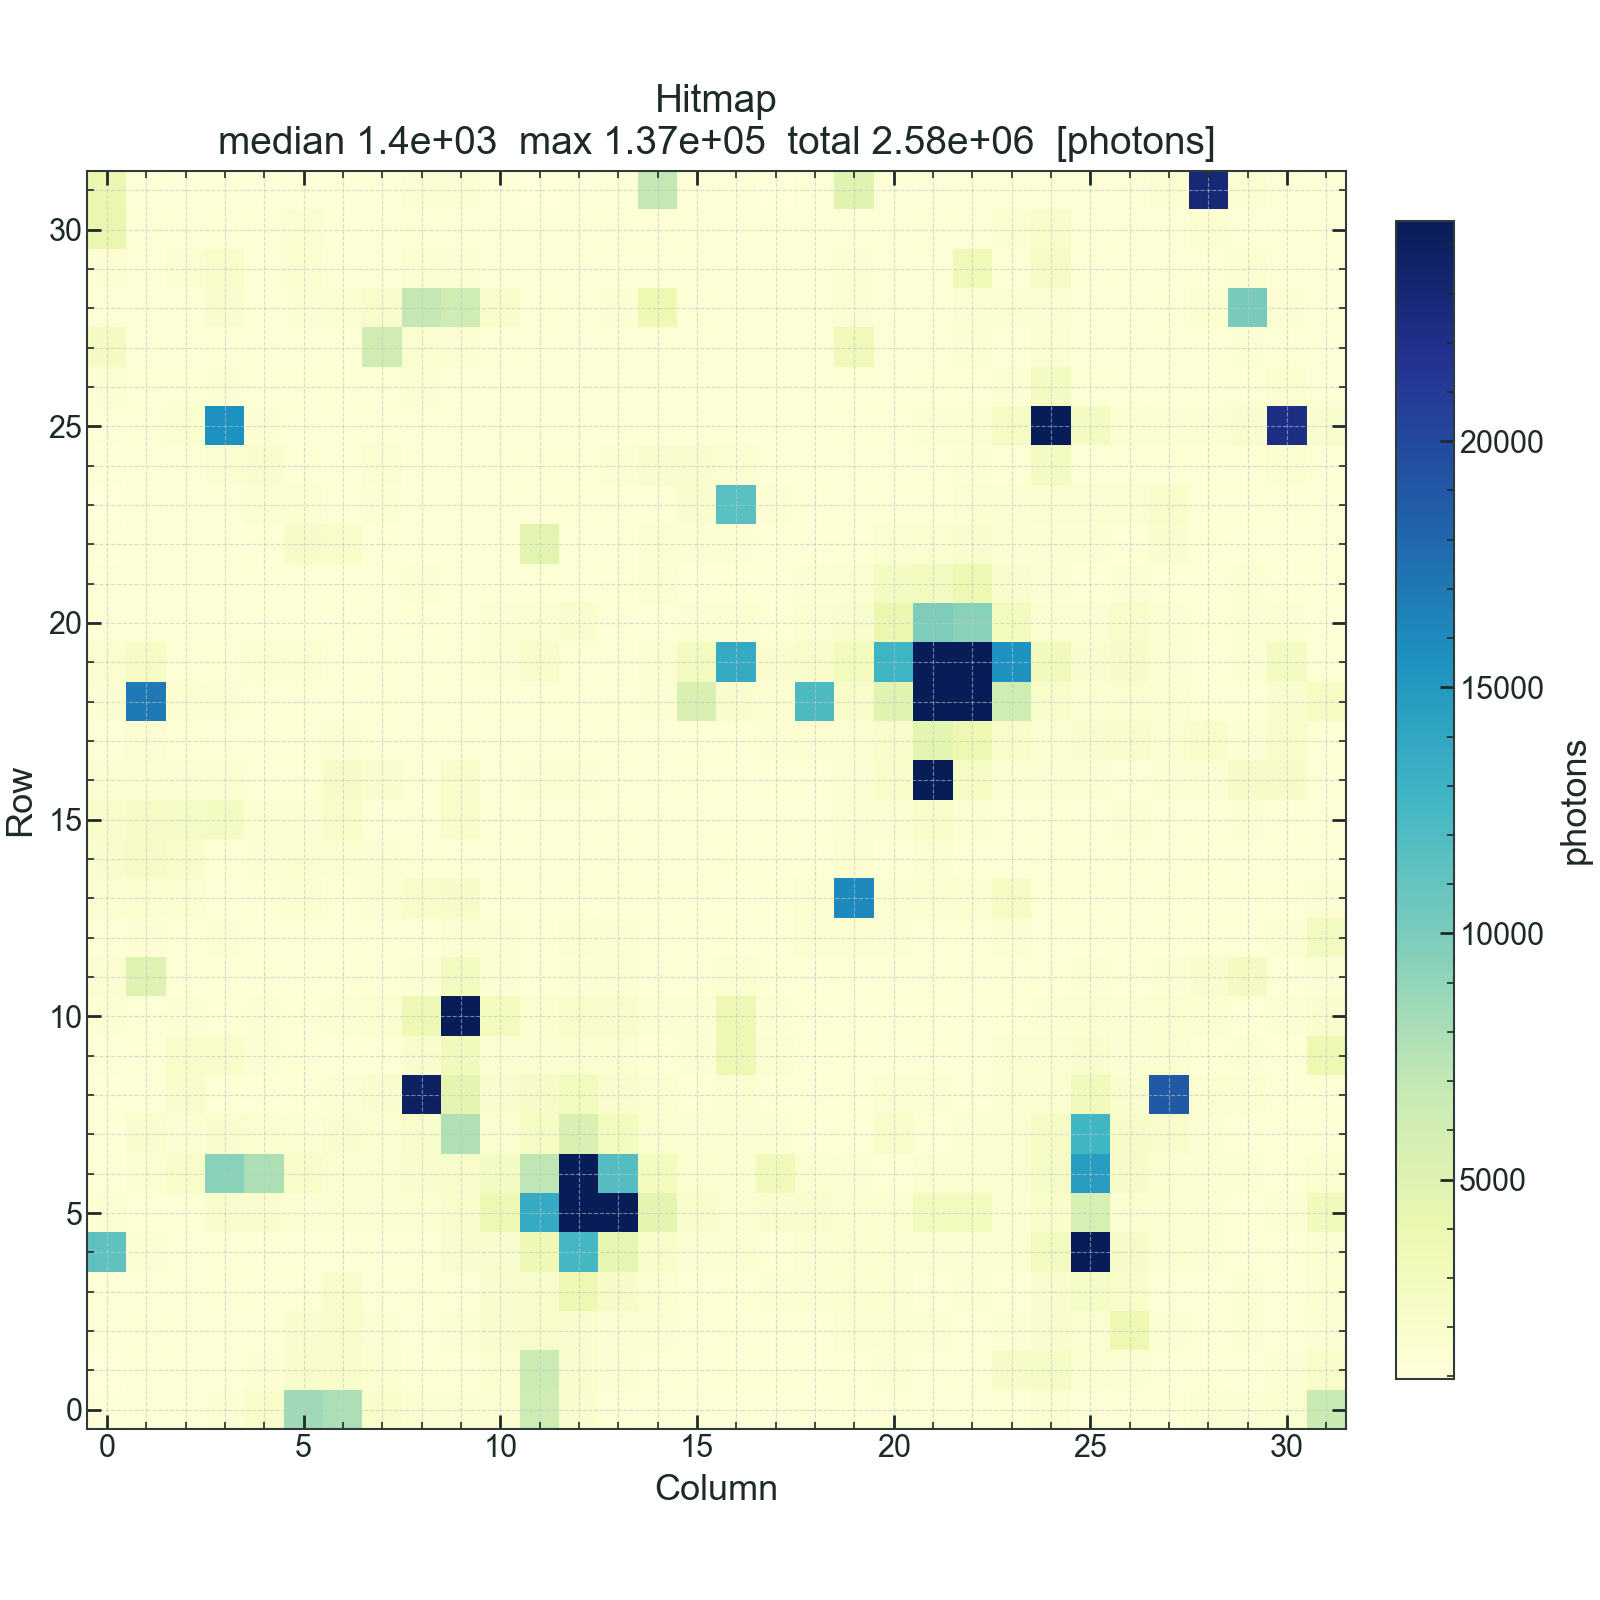

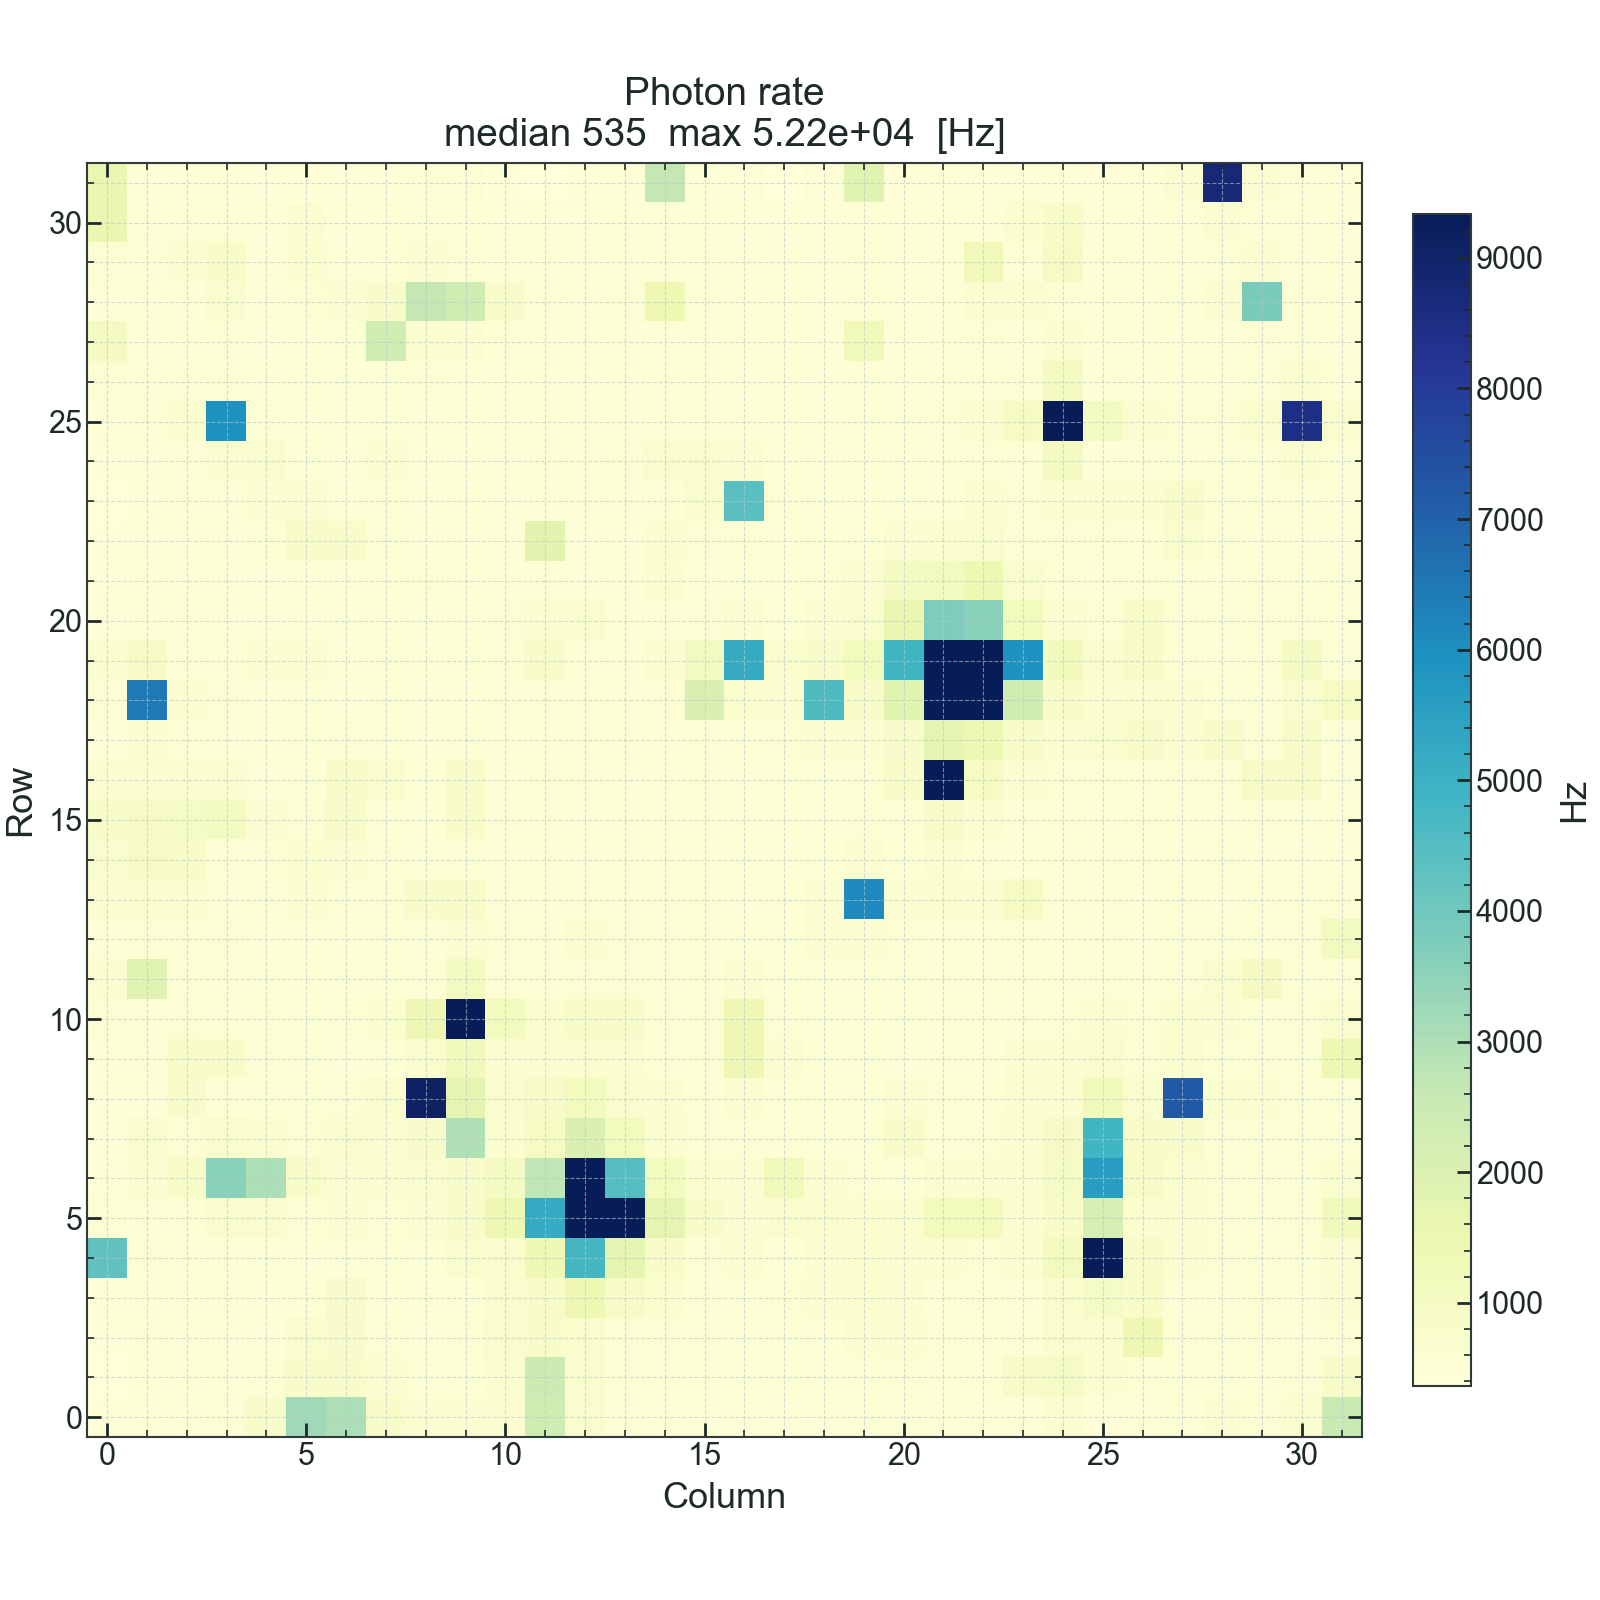

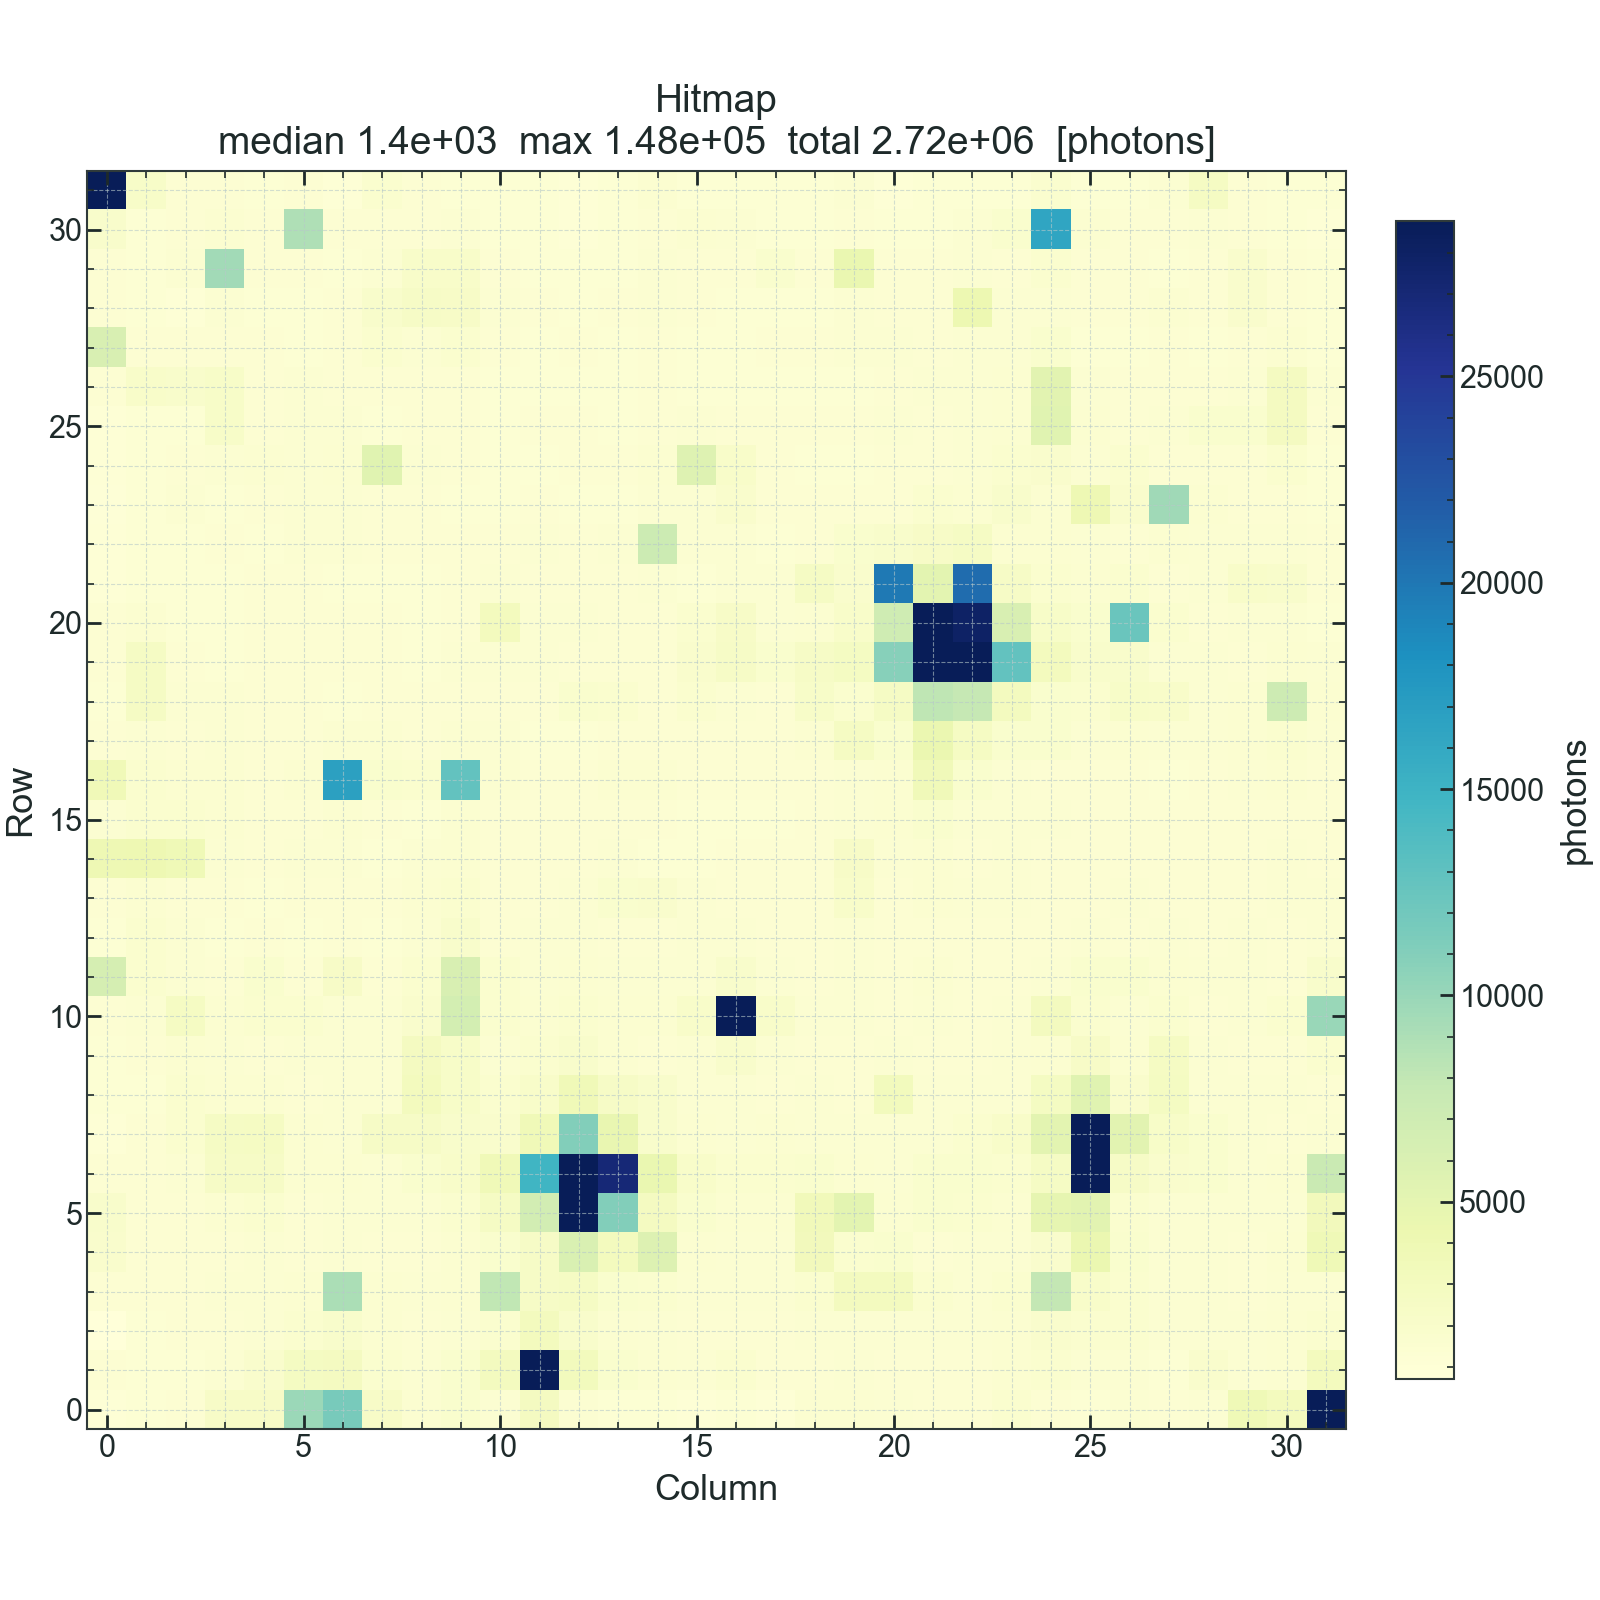

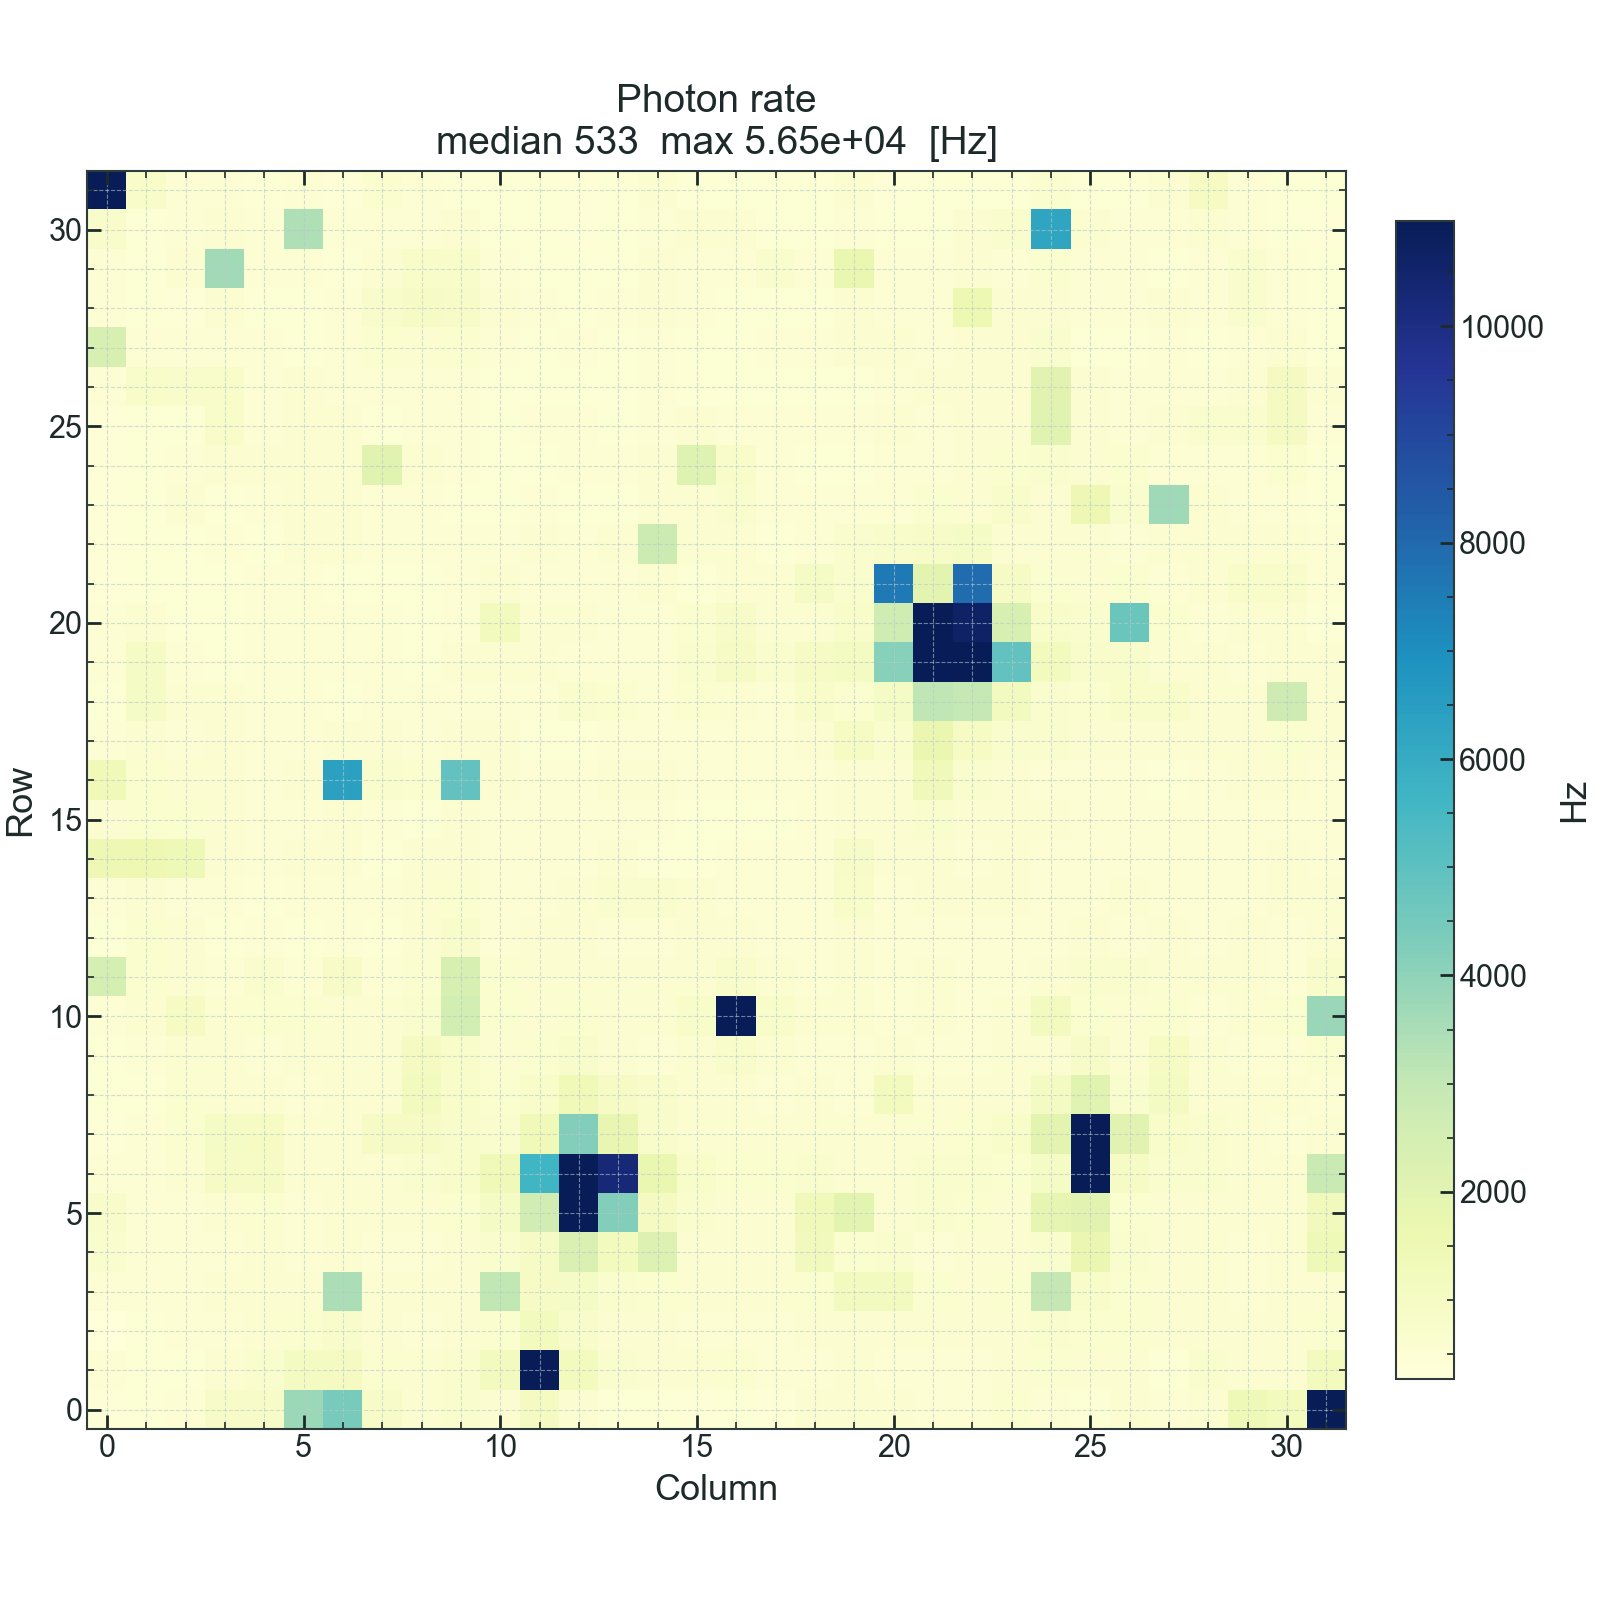

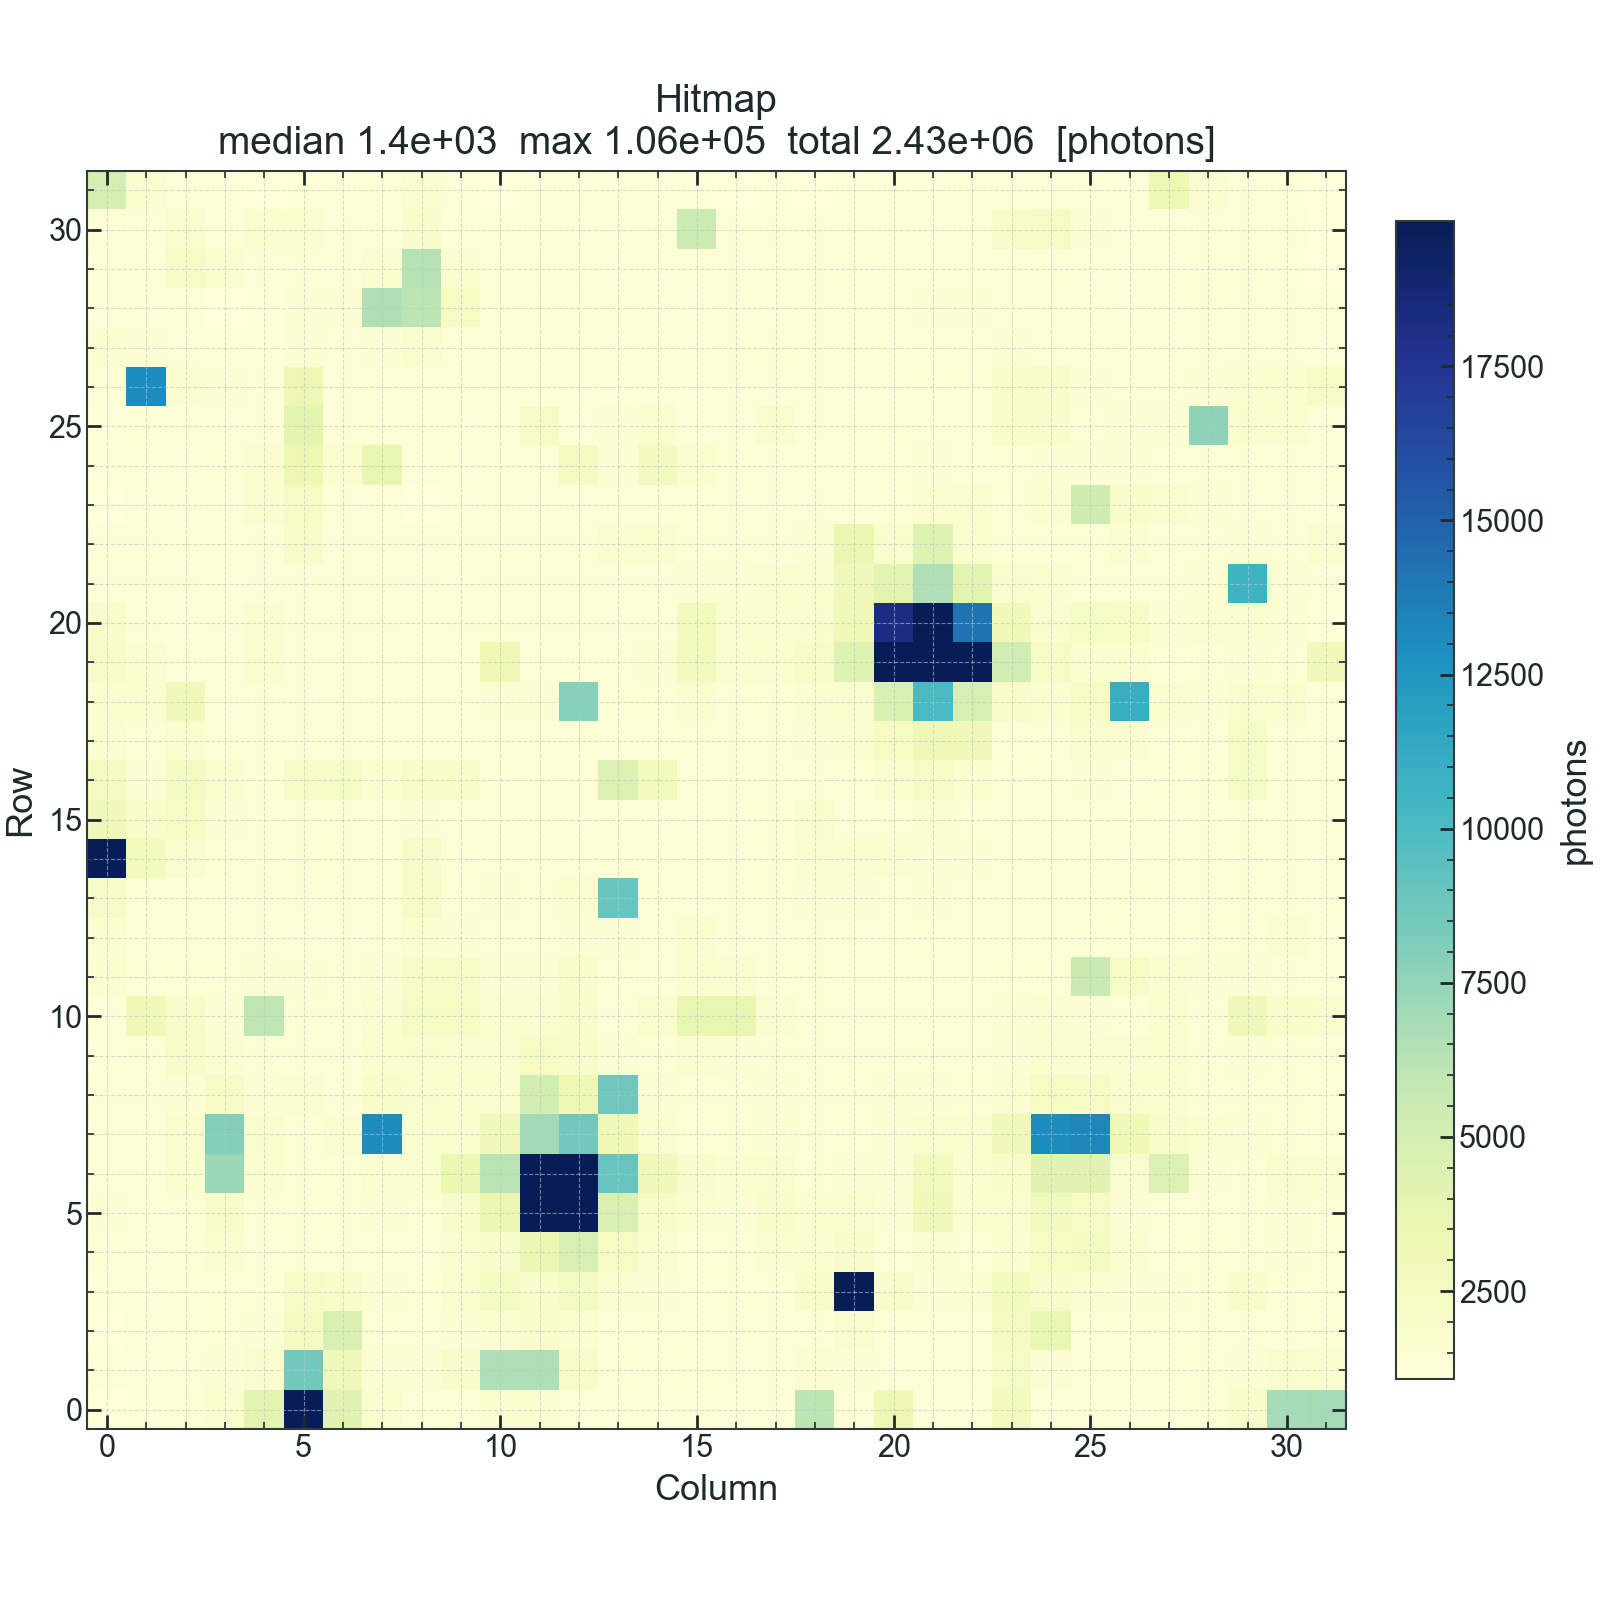

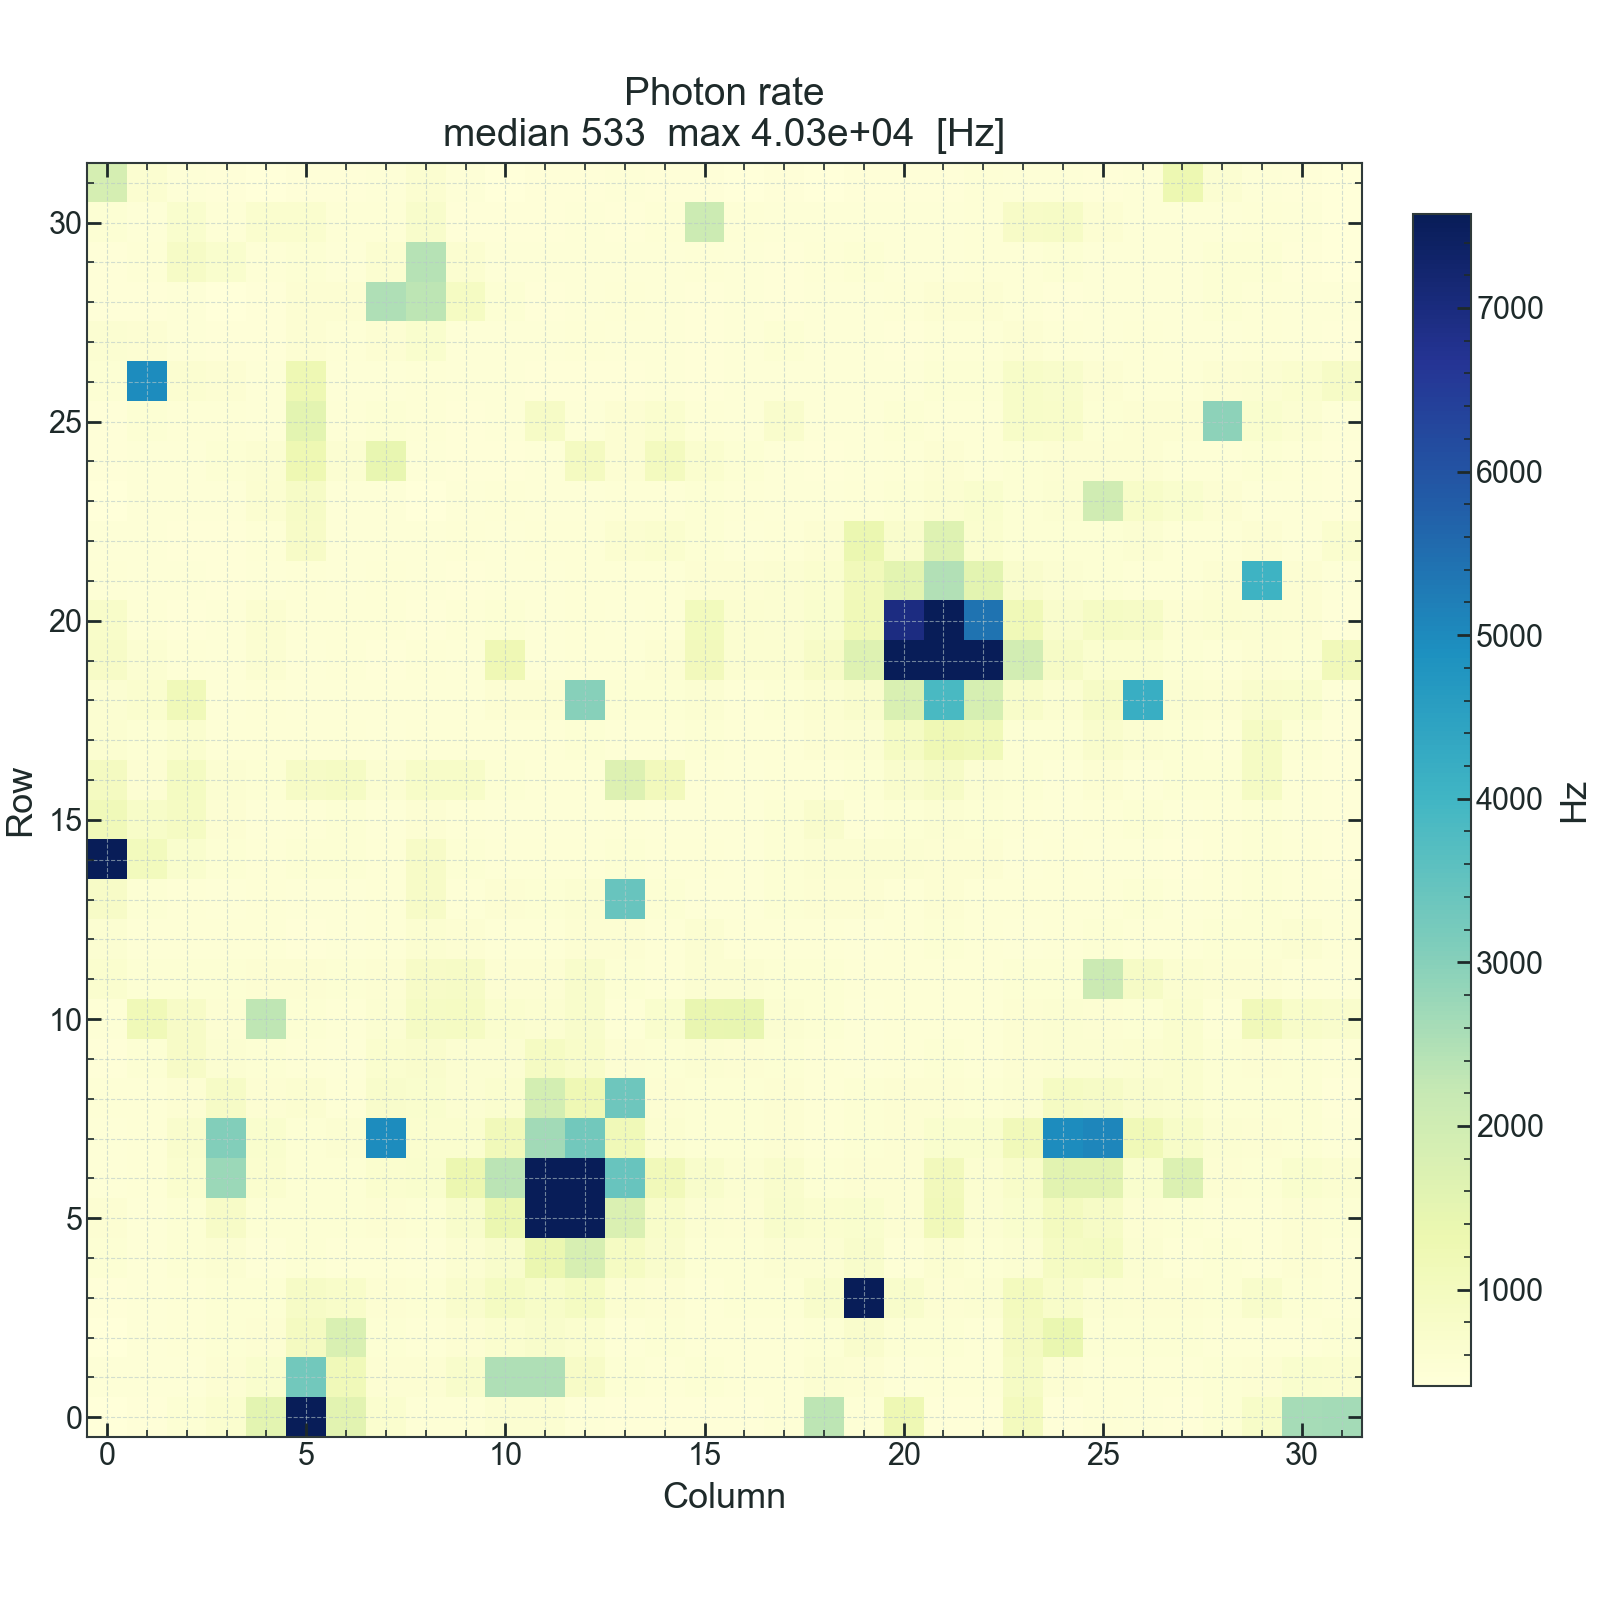

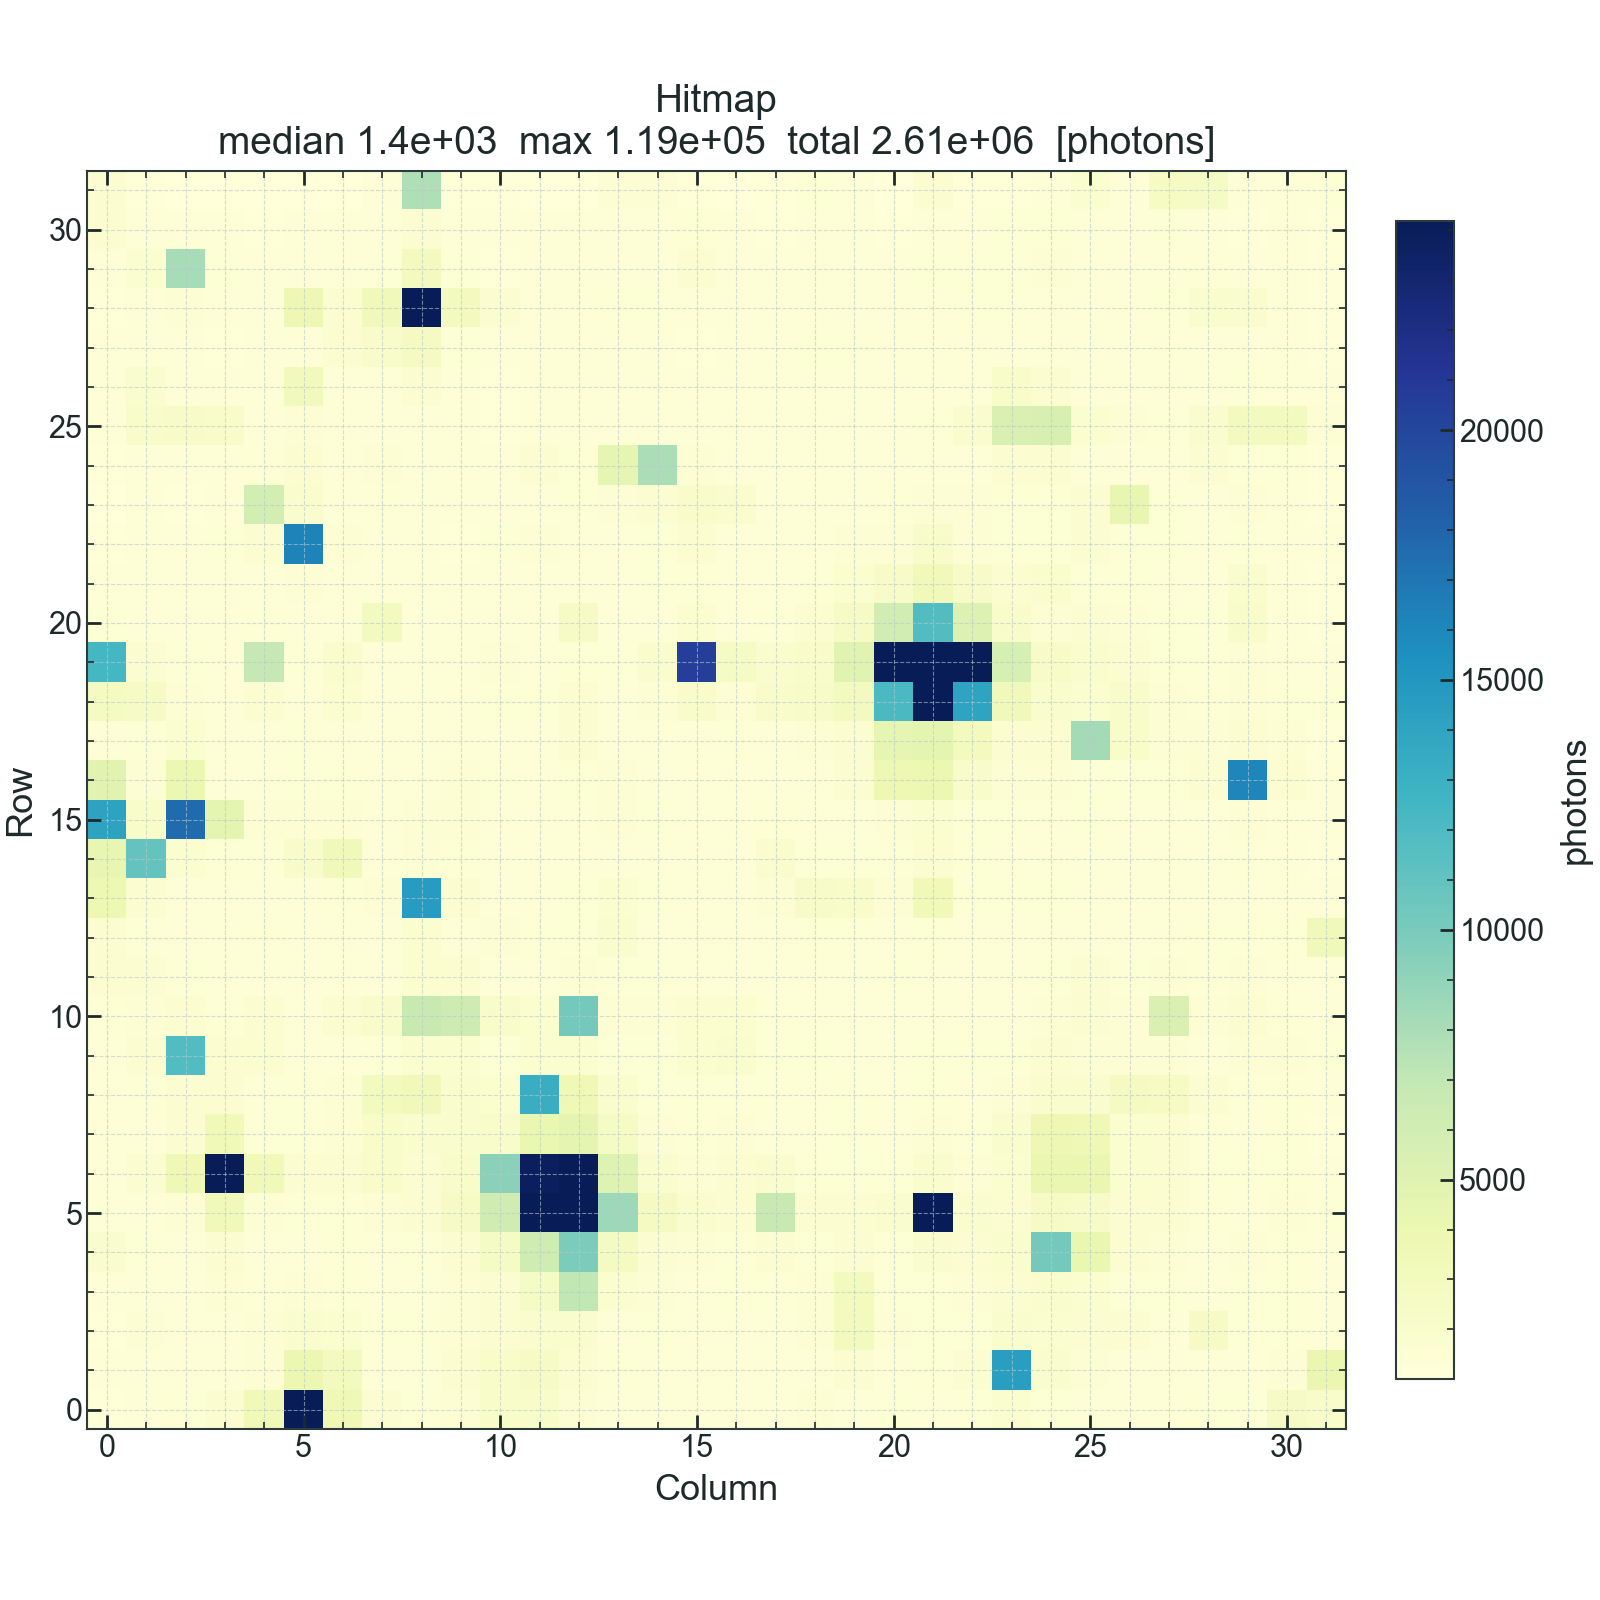

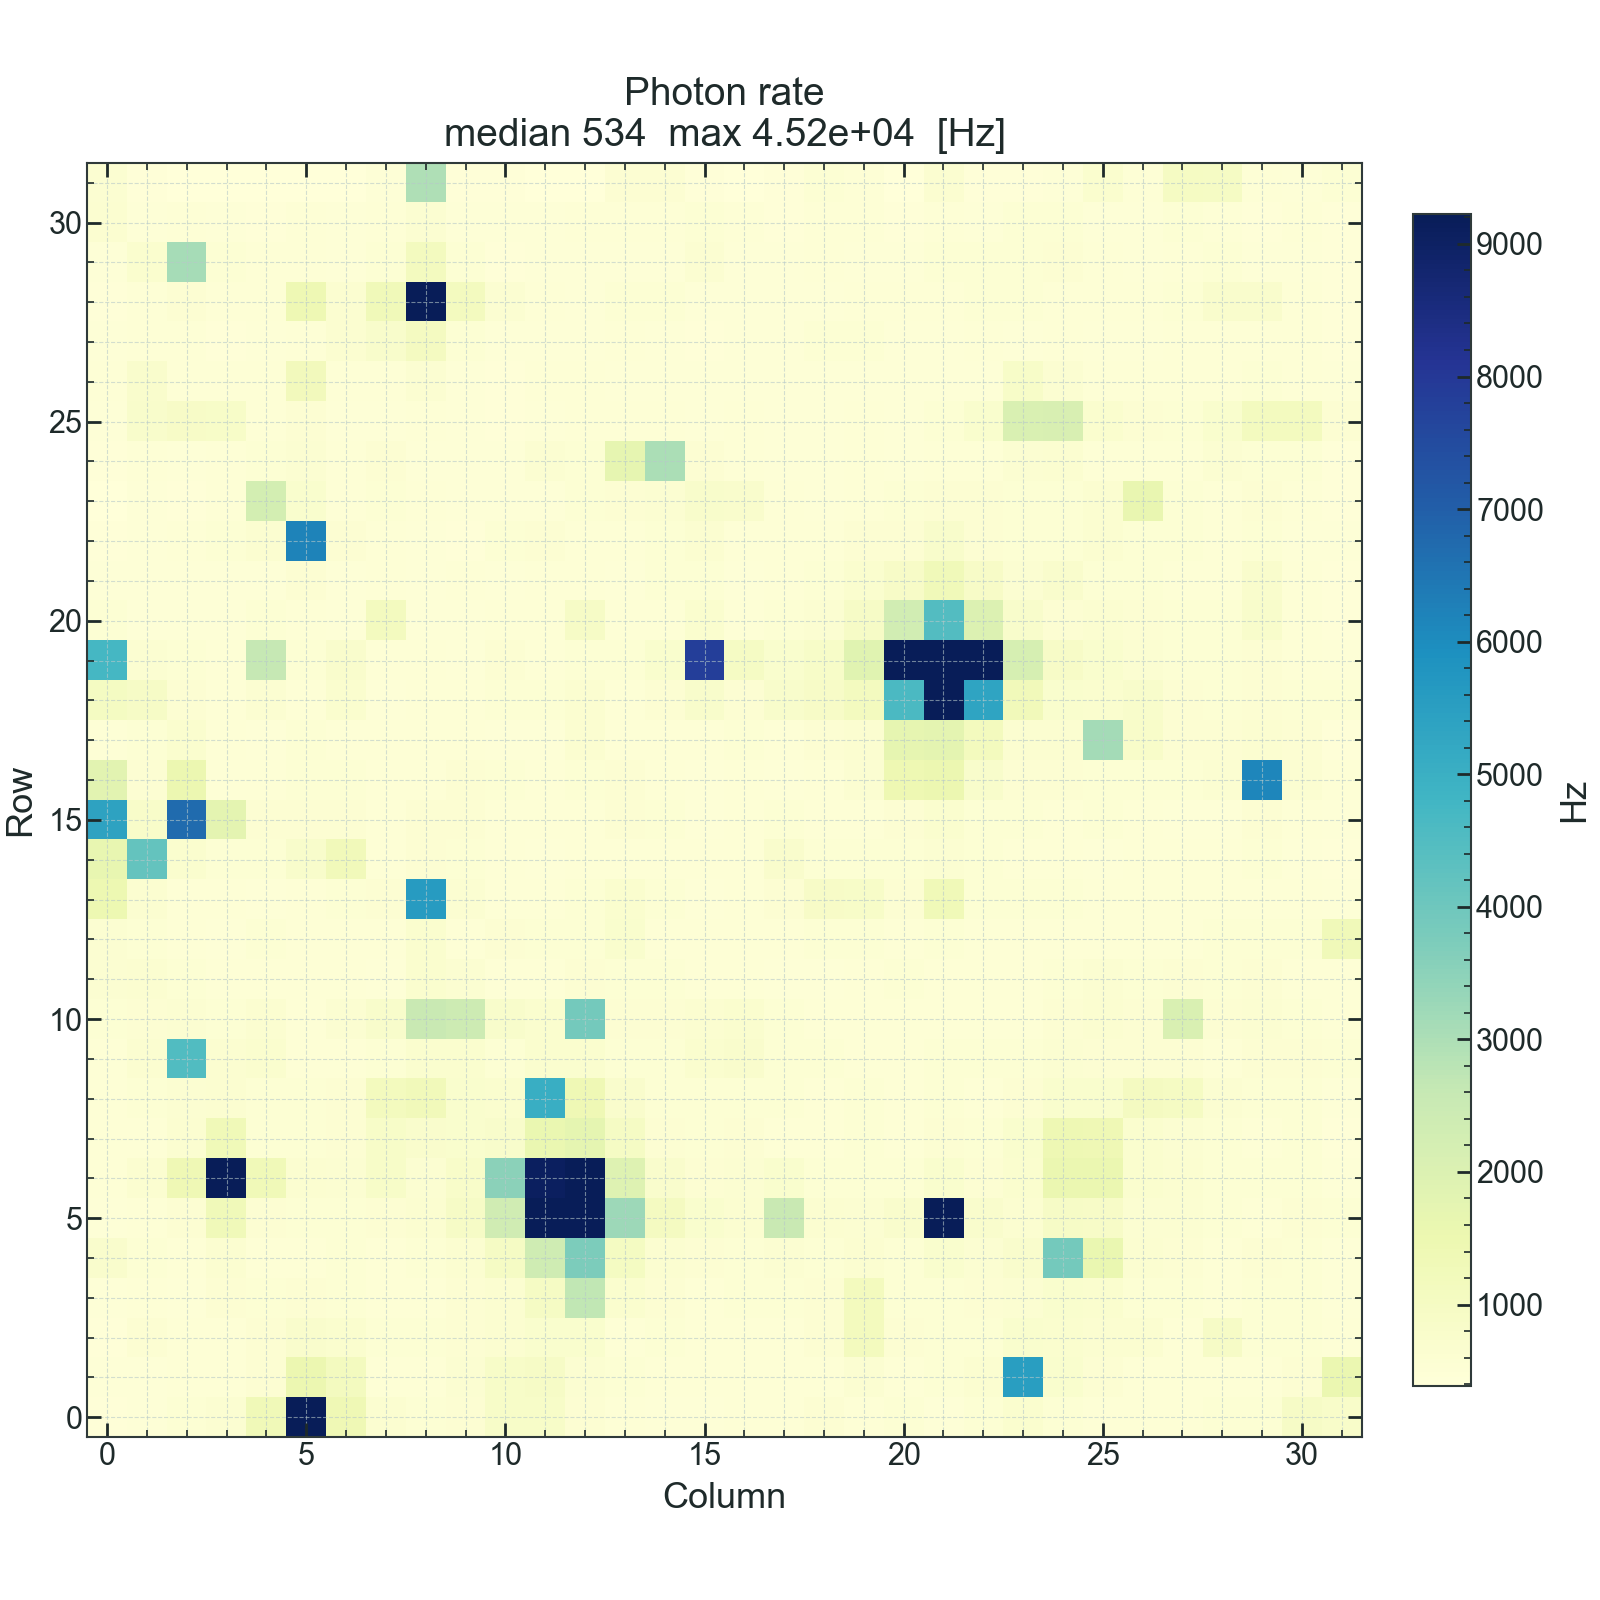

In [4]:
counts, rate = hm.plot_hitmap(path, tag)  # rate in Hz
# hot pixels flatten the colour scale; it is clipped at the 99th percentile by default
# counts, rate = hm.plot_hitmap(path, tag, clip_colorbar_to=None, cmap="viridis")
show_figures(path, "hitmap")

## 4. What the numbers mean

A `...T` pixel records at most one photon per frame. Its rate therefore tops
out at one per cycle (about 111 kHz per macropixel) and under-reports as it gets
close. Read it as a detection rate per second of acquisition, not as the photon
flux during the open shutter.

In [5]:
from dapkel.core import store, timing

_, meta = store.load_map(path, kind="hitmap", tag=tag)
ceiling_hz = 1 / max(meta["frame_live_s"], timing.FREE_RUNNING_US * 1e-6)
print(
    f"rate median {np.nanmedian(rate):.3g} Hz, max {np.nanmax(rate):.3g} Hz "
    f"({np.nanmax(rate) / ceiling_hz * 100:.0f} % of the {ceiling_hz / 1e3:.0f} kHz ceiling)"
)

rate median 1.69e+03 Hz, max 7.89e+04 Hz (71 % of the 111 kHz ceiling)


## 5. Find the bright spots

For an SPDC run, the two brightest blobs are the signal and idler candidates
for [coincidences](06_coincidences.ipynb). Read them off the rate map:

In [6]:
order = np.argsort(rate, axis=None)[::-1][:10]
brightest = [tuple(int(i) for i in np.unravel_index(k, rate.shape)) for k in order]
print(brightest)  # (row, col), brightest first

[(19, 21), (5, 12), (6, 12), (0, 5), (19, 22), (7, 25), (6, 3), (6, 11), (0, 31), (20, 21)]


This is only a starting point. Look at the figure and choose blobs that are
physically separate, not just the brightest single pixels. Then draw them on
the rate map to check the choice: every macropixel inside a rectangle goes into
that blob.

signal = [(r, c) for r in range(5, 7) for c in range(11, 13)]
idler = [(r, c) for r in range(18, 21) for c in range(20, 23)]


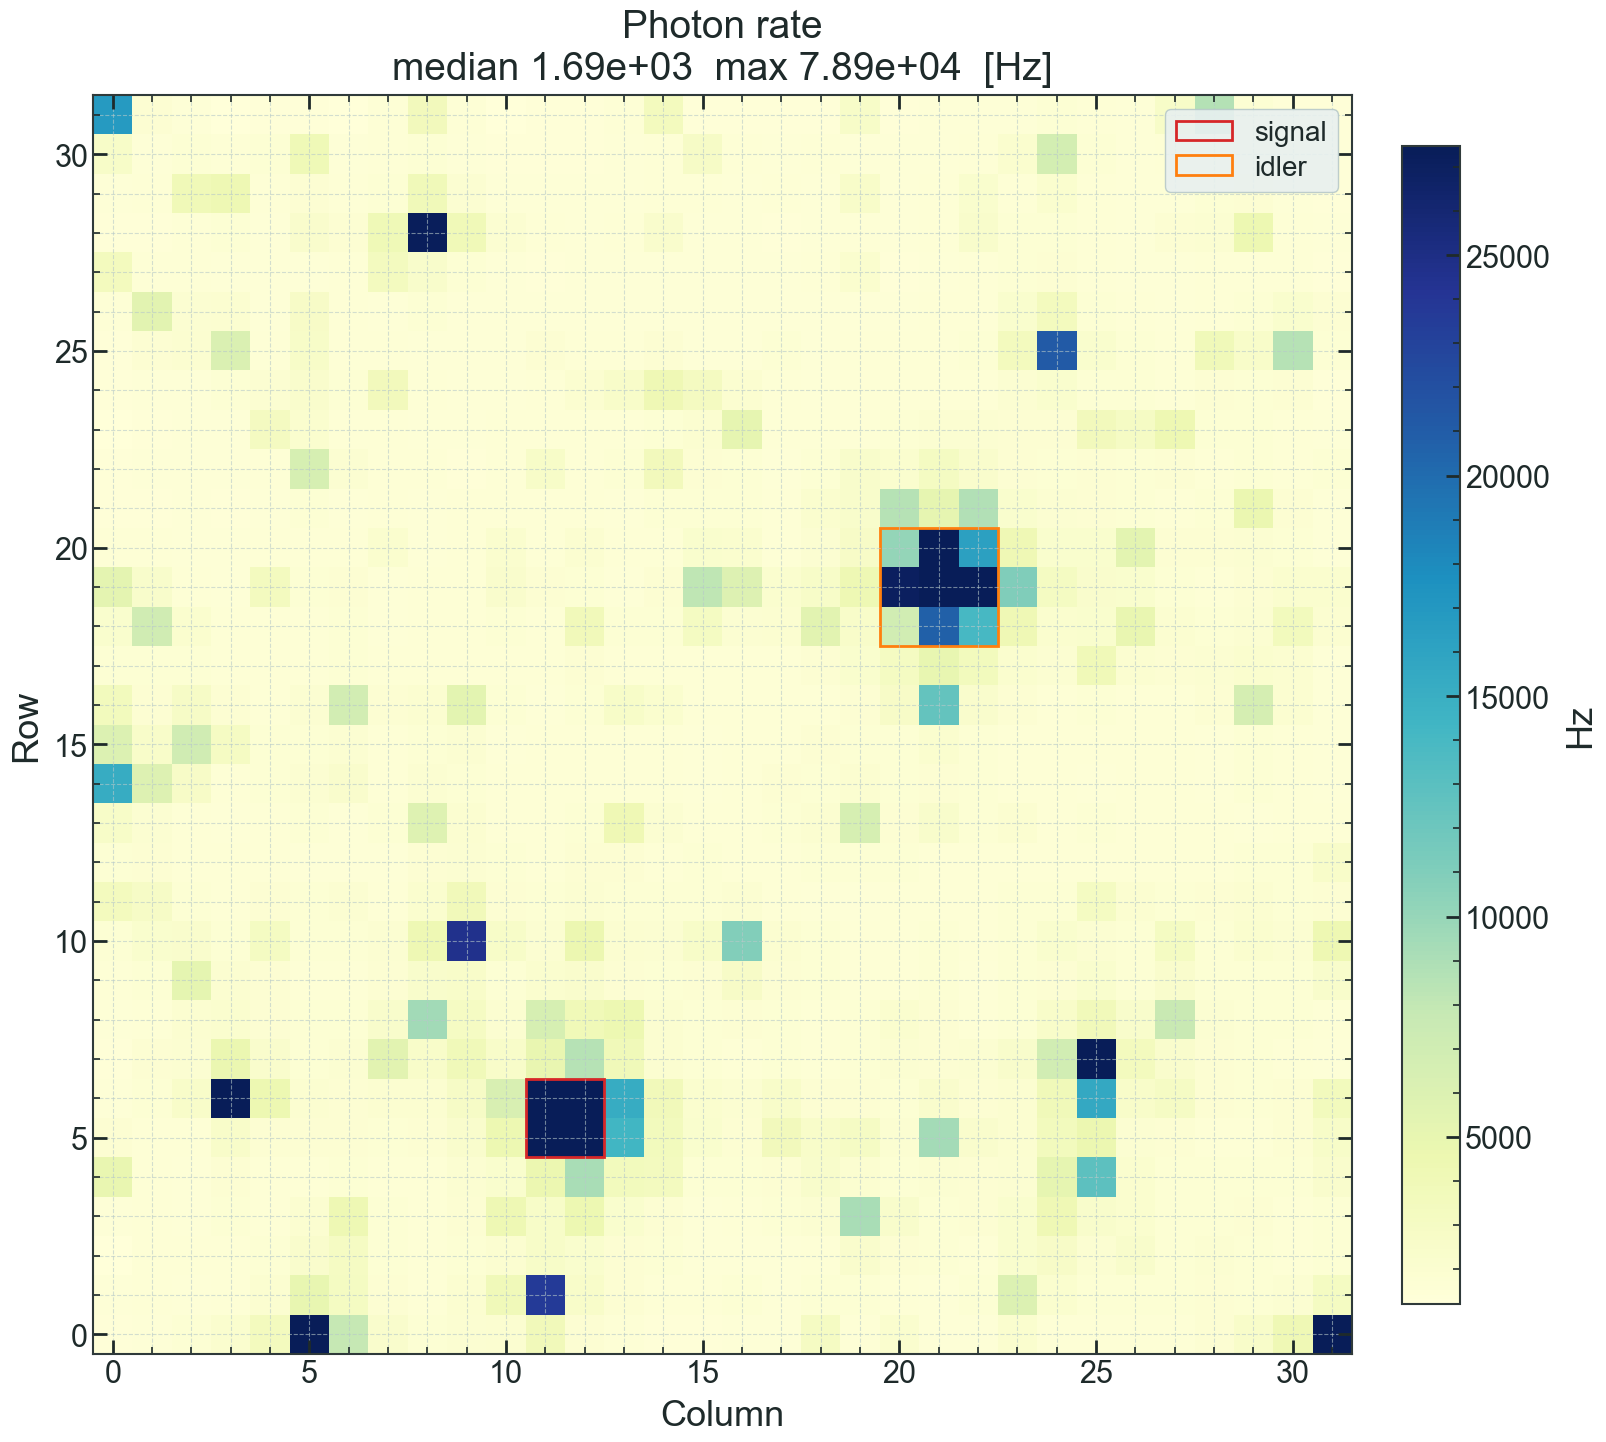

In [7]:
from matplotlib.patches import Rectangle

from dapkel.core import plots

# the two SPDC blobs, as the rows and columns they span
signal_rows, signal_cols = range(5, 7), range(11, 13)
idler_rows, idler_cols = range(18, 21), range(20, 23)
signal = [(r, c) for r in signal_rows for c in signal_cols]
idler = [(r, c) for r in idler_rows for c in idler_cols]

median, maximum, _ = plots.map_stats(rate)
fig = plots.sensor_map(
    rate, title=f"Photon rate\nmedian {median:.3g}  max {maximum:.3g}  [Hz]", clabel="Hz"
)
ax = fig.axes[0]
for rows, cols, label, color in (
    (signal_rows, signal_cols, "signal", "tab:red"),
    (idler_rows, idler_cols, "idler", "tab:orange"),
):
    # pixel (r, c) is centred on integer coordinates, so its edges sit at +-0.5
    ax.add_patch(
        Rectangle(
            (cols.start - 0.5, rows.start - 0.5),
            len(cols),
            len(rows),
            fill=False,
            edgecolor=color,
            linewidth=2,
            label=label,
        )
    )
ax.legend(loc="upper right")

# ready to paste into example 6
print(f"signal = [(r, c) for r in {signal_rows} for c in {signal_cols}]")
print(f"idler = [(r, c) for r in {idler_rows} for c in {idler_cols}]")

The SPDC pairs split between the two blobs: one photon of each pair lands in
the signal blob, its partner in the idler blob. Taking every macropixel of
each blob keeps all signal and all idler photons, whichever pixel within the
blob a photon hit.

## Next

Paste the two printed lines into [coincidences](06_coincidences.ipynb). It
histograms the arrival-time differences between the signal and idler pixels and
fits the coincidence peak.